# Two-region SIRD DINN with directional population movement

Kingsley Chimuanya Ukandu | Step 3 | October 11, 2026

This notebook implements the two-region stage through `src/two_region_sird.py` and
displays the recorded synthetic validation. All eight states and the initial state
are known. There are six disease rates and two directional movement rates.

States are fractions of the **combined initial population**. Initial regional
reference populations are $p_1=0.6$, $p_2=0.4$. Incidence is
$\beta_jS_jI_j/p_j$ with fixed reference denominators. Susceptible, infected, and
recovered states move; deceased states stay in the region where recorded.

The state transform enforces nonnegative states, combined population balance, and
the exact initial state. Equations are a soft residual penalty. Deceased monotonicity
is not a hard neural constraint. The experiment does not use real surveillance or
mobility data and does not establish method superiority.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import torch
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from two_region_sird import (Configuration, TwoRegionDINN, simulate, train, diagnose,
    STATE_NAMES, RATE_NAMES, SYNTHETIC_RATES)
torch.set_num_threads(1)
RESULTS = ROOT / 'validation' / 'step3' / 'results'
protocol = json.loads((RESULTS / 'protocol.json').read_text())
print('Configuration:', protocol['configuration'])
print('State units:', protocol['model']['state_units'])
print('Validation seeds:', protocol['seeds'])

Configuration: {'horizon': 160.0, 'width': 48, 'depth': 3, 'gate_scale_days': 3.2, 'adam_steps': 8000, 'lbfgs_steps': 1000, 'learning_rate': 0.001, 'physics_weight': 0.0001, 'collocation_points': 161}
State units: Fractions of combined initial population, including cumulative deaths.
Validation seeds: [0, 1, 2]


## Load and verify an illustrative clean checkpoint

Seed 0 is used for the illustration; it was not selected by accuracy. Set
`RETRAIN = True` to reproduce a separate fit with the same fixed budget. The
default execution loads the recorded model and recomputes its diagnostics.

In [2]:
RETRAIN = False
times = np.arange(0., 160., 3.)
observations = simulate(times, SYNTHETIC_RATES)
if RETRAIN:
    model, training, history = train(times, observations, seed=0,
        output=ROOT / 'validation' / 'step3' / 'notebook_run')
else:
    folder = RESULTS / 'clean' / 'seed_0'
    training = json.loads((folder / 'training.json').read_text())
    model = TwoRegionDINN(Configuration(**training['configuration']), training['initial_rates'])
    model.load_state_dict(torch.load(folder / 'weights.pt', weights_only=True))
grid = np.linspace(0., 160., 641)
metrics, prediction, truth, residual = diagnose(model, grid)
print('Rate       true           inferred       relative error %')
for name, value in zip(RATE_NAMES, SYNTHETIC_RATES):
    print(f"{name:8s} {value:.9f}    {metrics['parameters'][name]:.9f}    {metrics['relative_errors_percent'][name]:.6f}")
for key in ['trajectory_rmse', 'negative_entries', 'conservation_max_abs_error',
            'initial_max_abs_error', 'residual_max_abs_per_day', 'minimum_D_derivative_per_day']:
    print(key, metrics[key])

Rate       true           inferred       relative error %
beta1    0.500000000    0.499479655    0.104069
gamma1   0.200000000    0.200095715    0.047858
omega1   0.071428571    0.071280074    0.207896
beta2    0.380000000    0.380055895    0.014709
gamma2   0.160000000    0.159997159    0.001776
omega2   0.035000000    0.034958857    0.117552
tau12    0.015000000    0.015038988    0.259923
tau21    0.010000000    0.010002102    0.021025
trajectory_rmse 0.0002371616211406511
negative_entries 0
conservation_max_abs_error 4.440892098500626e-16
initial_max_abs_error 0.0
residual_max_abs_per_day 0.000826742756648257
minimum_D_derivative_per_day -7.604359616362236e-06


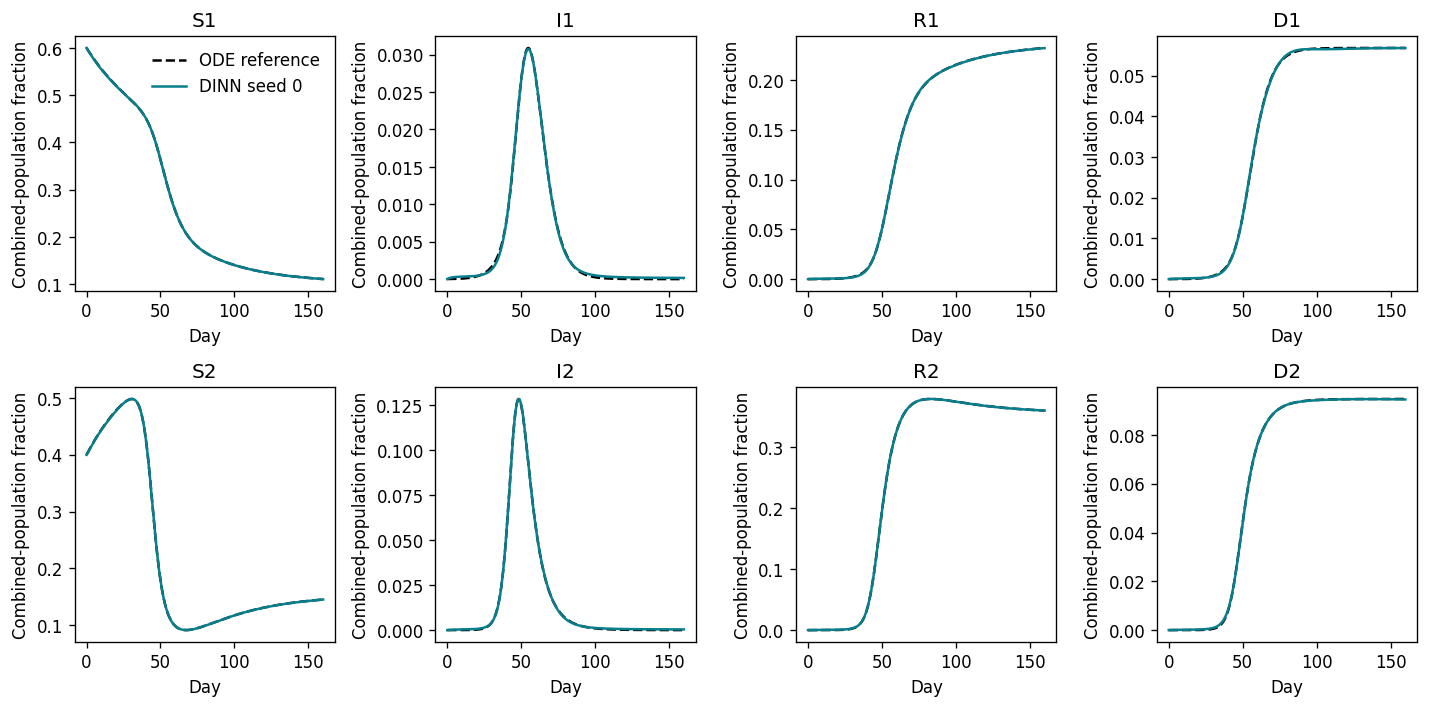

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for j, name in enumerate(STATE_NAMES):
    ax = axes.flat[j]
    ax.plot(grid, truth[:, j], 'k--', label='ODE reference')
    ax.plot(grid, prediction[:, j], color='#087f8c', label='DINN seed 0')
    ax.set_title(name)
    ax.set_xlabel('Day')
    ax.set_ylabel('Combined-population fraction')
axes[0, 0].legend(frameon=False)
fig.tight_layout()
plt.show()

## All nine runs and the ODE comparator

The reported ranges are descriptive, not confidence intervals. Each noisy or missing
condition uses one fixed dataset. Conventional calibration is a strong comparator in
these model-correct synthetic experiments.

In [4]:
summary = json.loads((RESULTS / 'neural_summary.json').read_text())
print('Data      seed  max disease error %  tau12 error %  tau21 error %  trajectory RMSE')
for row in summary:
    e = row['relative_errors_percent']
    disease = max(e[n] for n in RATE_NAMES[:6])
    print(f"{row['case']:8s}  {row['seed']}       {disease:.6f}         {e['tau12']:.6f}       {e['tau21']:.6f}       {row['trajectory_rmse']:.6g}")
print('\nODE calibration:')
for case in ['clean', 'noisy', 'missing']:
    ode = json.loads((RESULTS / case / 'ode_baseline.json').read_text())
    print(case, 'max rate error %', max(ode['relative_errors_percent'].values()),
        'trajectory RMSE', ode['trajectory_rmse'], 'converged', ode['optimizer_success'])

Data      seed  max disease error %  tau12 error %  tau21 error %  trajectory RMSE
clean     0       0.207896         0.259923       0.021025       0.000237162
clean     1       0.265291         0.091564       0.300501       0.00026085
clean     2       0.187635         0.134305       0.438345       0.000253375
noisy     0       2.136687         0.183439       0.533226       0.000359596
noisy     1       2.039897         0.441114       0.777803       0.000359228
noisy     2       2.154200         0.625796       1.033084       0.000368121
missing   0       0.286103         0.205075       0.082980       0.000245626
missing   1       0.339910         0.202027       0.467047       0.000267657
missing   2       0.279118         0.318207       0.649401       0.000265088

ODE calibration:
clean max rate error % 1.5873413694578176e-11 trajectory RMSE 3.4311804425041614e-15 converged True
noisy max rate error % 0.28159800342662994 trajectory RMSE 0.000104546616131053 converged True
missing max 

## Model checks and an identifiability limit

Zero movement reduces to the original SIRD system independently in each region.
Transport without disease agrees with a matrix exponential. Equal regions with
identical epidemics and symmetric movement have zero net movement; changing the
common movement scale then leaves all trajectories unchanged. This prevents its
identification in that setup.

In [5]:
checks = json.loads((RESULTS / 'model_checks.json').read_text())
print('Model checks:', checks['status'])
for name, values in checks['results'].items():
    print(name, values)
verification = json.loads((RESULTS / 'verification.json').read_text())
print('\nCheckpoint and dataset verification:', verification['status'])
print('Pilot vs fresh clean seed-0 metrics identical:',
      verification['pilot_vs_fresh_clean_seed0_metrics_identical'])

Model checks: PASS
population_balance {'global_rhs_sum_max_abs': 4.163336342344337e-17, 'regional_rhs_balance_max_abs': 3.2959746043559335e-17}
boundary_nonnegativity {'tested_boundary_states': 1600, 'minimum_derivative': 2.1122014794364e-06}
mobility_convention {'matrix': [[-0.015, 0.01], [0.015, -0.01]], 'deceased_compartments_have_no_movement_terms': True}
zero_mobility {'max_abs_rhs_difference_from_original_SIRD': 2.7755575615628914e-17, 'max_abs_trajectory_difference_from_independent_original_SIRD': 3.1708800585228403e-09}
transport_only {'max_abs_difference_from_matrix_exponential': 4.203043468820056e-11, 'deceased_counts_constant': True}
symmetric_limit {'max_abs_aggregate_difference_from_single_SIRD': 1.59701218915842e-09, 'max_abs_difference_with_sixfold_common_movement_rate': 0.0, 'interpretation': 'Equal region sizes and identical epidemic states with symmetric flows leave the common movement scale unidentifiable.'}
infection_transport {'region2_initial_infected': 0.0, 'regi

## Scope

This is a synthetic two-region mobility proof of implementation. Regional populations
are variable; the combined accounted population is conserved. Recovered counts in one
region can decline due to outward movement. Small neural decreases in deceased states
are approximation errors and are retained in diagnostics. A multipatch SIS model,
real-data observation models, uncertainty analysis, and practical forecasting remain
future work. See the Step 3 report and `validation/step3/REPRODUCE.md` for the fixed
protocol and reproduction instructions.